# Digital Image Processing – Lab Task 03
## Image Enhancement and Intensity Transformations

**Course:** Digital Image Processing Lab  
**Lab Task:** 03  
**Student Name:** Kamal Ali Akmal 
**Roll Number:** 2024-SE-38
**Session:** 2024–28

> **Input-image note:** `input_image.png` is a 512 × 512 demonstration grayscale image included with this notebook so the code can run immediately. The lab manual requires a personally selected JPG/PNG image of at least 300 × 300 pixels.

## 1. Import libraries and load the image

The original image is kept unchanged. Image operations are performed on copies. Arithmetic is carried out in a wider type (`int16`, `int32`, or `float32`) and values are clipped to 0–255 before conversion to `uint8`.

Shape: (512, 512)
Data type: uint8
Minimum intensity: 35
Maximum intensity: 245


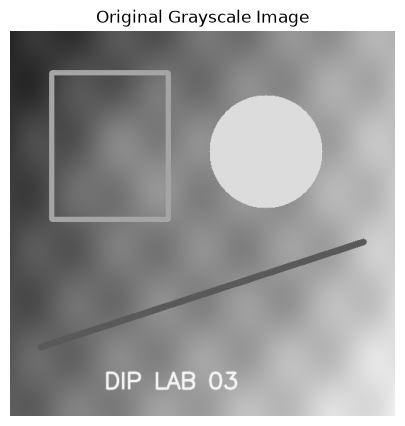

In [3]:
import cv2 
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

IMAGE_PATH = Path("input_image.png")
if not IMAGE_PATH.exists():
    raise FileNotFoundError("Place your personal grayscale/RGB JPG or PNG image beside this notebook as input_image.png.")

loaded = cv2.imread(str(IMAGE_PATH), cv2.IMREAD_UNCHANGED)
if loaded is None:
    raise ValueError("OpenCV could not read the image. Check the file format and path.")

if loaded.ndim == 2:
    original = loaded.copy()
elif loaded.ndim == 3:
    # OpenCV loads color images in BGR order.
    original = cv2.cvtColor(loaded, cv2.COLOR_BGR2GRAY)
else:
    raise ValueError("Unsupported image dimensions.")

if original.dtype != np.uint8:
    raise TypeError(f"Expected an 8-bit image (uint8), but received {original.dtype}. Convert your image to 8-bit first.")

if original.shape[0] < 300 or original.shape[1] < 300:
    raise ValueError(f"Image must be at least 300 x 300 pixels; received {original.shape}.")

print("Shape:", original.shape)
print("Data type:", original.dtype)
print("Minimum intensity:", int(original.min()))
print("Maximum intensity:", int(original.max()))

plt.figure(figsize=(6,5))
plt.imshow(original, cmap="gray", vmin=0, vmax=255)
plt.title("Original Grayscale Image")
plt.axis("off")
plt.show()

## 2. Common display helper

In [4]:
def show_images(images, titles, cols=3, figsize=(14, 8)):
    rows = int(np.ceil(len(images) / cols))
    plt.figure(figsize=figsize)
    for i, (image, title) in enumerate(zip(images, titles), start=1):
        plt.subplot(rows, cols, i)
        plt.imshow(image, cmap="gray", vmin=0, vmax=255)
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

def safe_uint8(values):
    # Clip first, then convert. This prevents wraparound/overflow.
    return np.clip(values, 0, 255).astype(np.uint8)

# Practical 1 – Brightness adjustment

Formula: `s = r + β`. Positive β makes the image brighter; negative β makes it darker. Values outside 0–255 are clipped.

### Dry run

Input pixels: `[30, 80, 128, 180, 240]`

- For β = +40, raw values are `[70, 120, 168, 220, 280]`; after clipping: `[70, 120, 168, 220, 255]`.
- For β = −40, raw values are `[-10, 40, 88, 140, 200]`; after clipping: `[0, 40, 88, 140, 200]`.
- Detail is lost where values are clipped: 240 + 40 becomes 255, and 30 − 40 becomes 0. Different original values may collapse to the same endpoint.

beta=40: raw=[70, 120, 168, 220, 280], clipped/final uint8=[70, 120, 168, 220, 255]
beta=-40: raw=[-10, 40, 88, 140, 200], clipped/final uint8=[0, 40, 88, 140, 200]
Nested-loop result matches NumPy: True


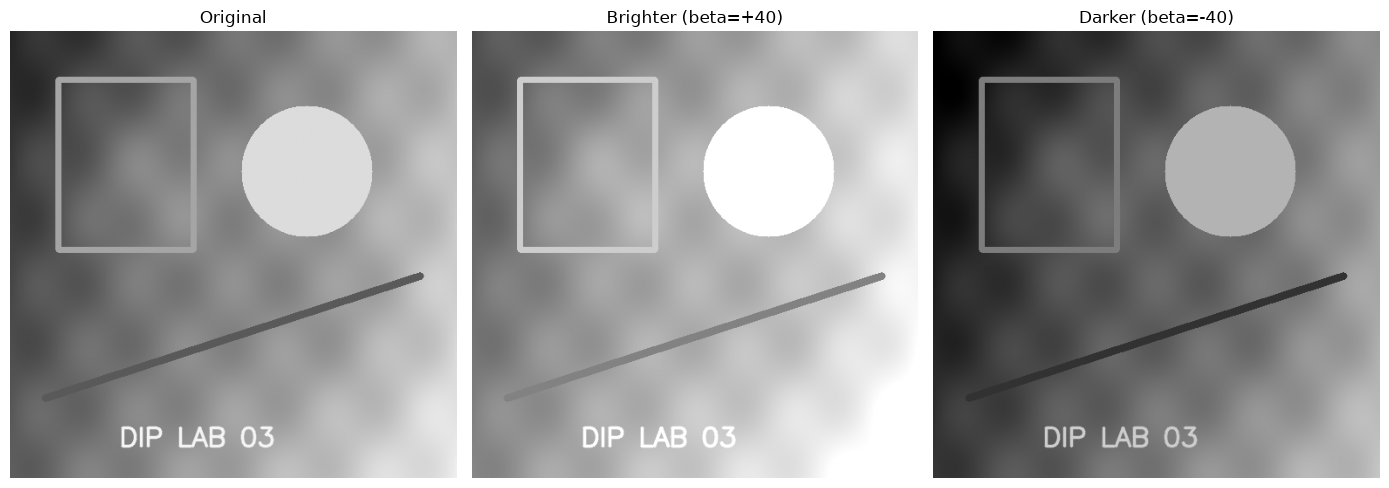

In [5]:
sample = np.array([30, 80, 128, 180, 240], dtype=np.int16)
for beta in (40, -40):
    raw = sample + beta
    result = safe_uint8(raw)
    print(f"beta={beta}: raw={raw.tolist()}, clipped/final uint8={result.tolist()}")

bright = safe_uint8(original.astype(np.int16) + 40)
dark = safe_uint8(original.astype(np.int16) - 40)

# Required nested-loop implementation for +40
bright_loop = np.empty_like(original)
rows, cols = original.shape
for i in range(rows):
    for j in range(cols):
        value = int(original[i, j]) + 40
        bright_loop[i, j] = min(255, max(0, value))

print("Nested-loop result matches NumPy:", np.array_equal(bright, bright_loop))
show_images([original, bright, dark],
            ["Original", "Brighter (beta=+40)", "Darker (beta=-40)"])

# Practical 2 – Linear contrast from zero

Formula: `s = αr + β`, where α = 1.5 and β = 0. Since α is greater than 1, intensity differences are expanded. Values above 255 saturate at 255.

### Dry run

For `[30, 80, 128, 180, 240]`, raw values are `[45, 120, 192, 270, 360]`. After clipping and truncation, the output is `[45, 120, 192, 255, 255]`. The last two pixels saturate; their original difference is lost.

Raw: [45.0, 120.0, 192.0, 270.0, 360.0]
Clipped/truncated: [45, 120, 192, 255, 255]


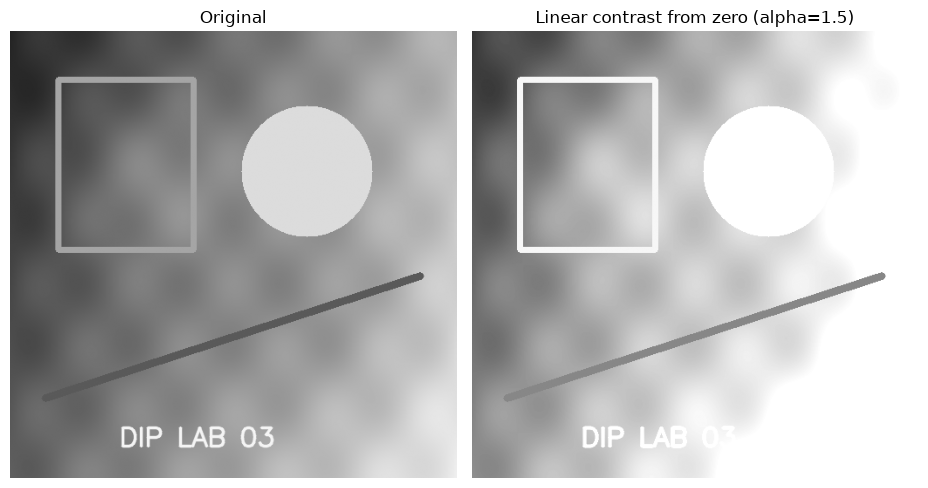

In [6]:
sample = np.array([30, 80, 128, 180, 240], dtype=np.float32)
raw = 1.5 * sample
print("Raw:", raw.tolist())
print("Clipped/truncated:", safe_uint8(raw).tolist())

contrast_zero = safe_uint8(1.5 * original.astype(np.float32))
show_images([original, contrast_zero],
            ["Original", "Linear contrast from zero (alpha=1.5)"])

# Practical 3 – Contrast centered at 128

Formula: `s = (r − 128)α + 128`. The midpoint 128 stays fixed for either α. With α = 1.5, values move farther from 128 (more contrast); with α = 0.5, values move toward 128 (less contrast).

### Dry run

Input: `[30, 80, 128, 180, 240]`

- α = 1.5: intermediate values `[-19, 56, 128, 206, 296]`; clipped output `[0, 56, 128, 206, 255]`.
- α = 0.5: intermediate values `[79, 104, 128, 154, 184]`; output `[79, 104, 128, 154, 184]`.
- At r = 128, output remains 128 because it is the center of the transformation.

alpha=1.5: intermediate=[-19.0, 56.0, 128.0, 206.0, 296.0], final=[0, 56, 128, 206, 255]
alpha=0.5: intermediate=[79.0, 104.0, 128.0, 154.0, 184.0], final=[79, 104, 128, 154, 184]


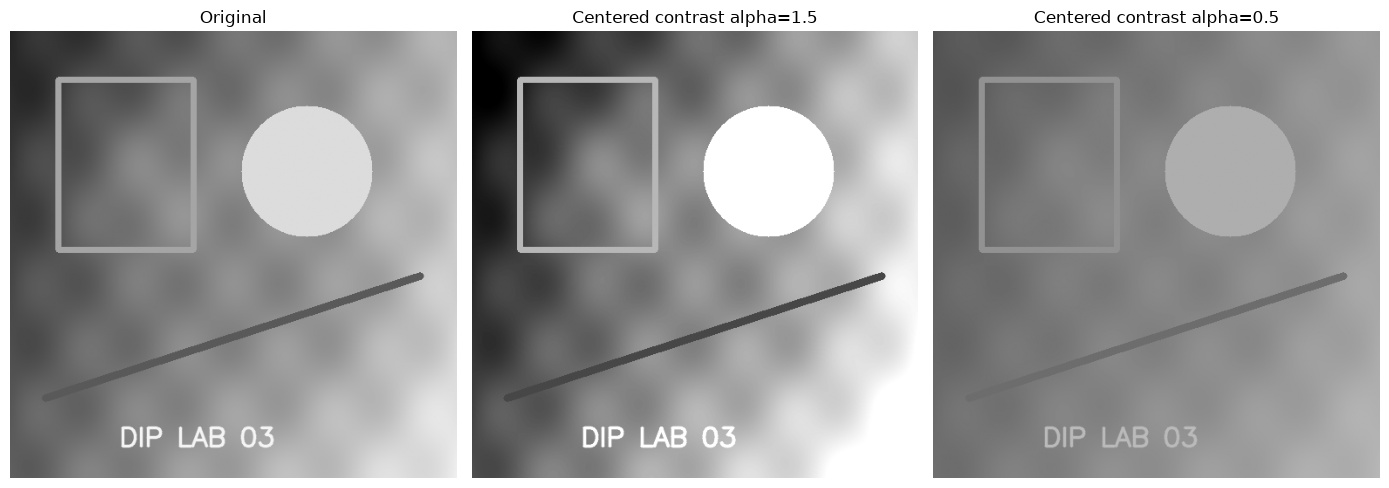

In [7]:
sample = np.array([30, 80, 128, 180, 240], dtype=np.float32)
for alpha in (1.5, 0.5):
    intermediate = (sample - 128) * alpha + 128
    print(f"alpha={alpha}: intermediate={intermediate.tolist()}, final={safe_uint8(intermediate).tolist()}")

centered_high = safe_uint8((original.astype(np.float32) - 128) * 1.5 + 128)
centered_low = safe_uint8((original.astype(np.float32) - 128) * 0.5 + 128)
show_images([original, centered_high, centered_low],
            ["Original", "Centered contrast alpha=1.5", "Centered contrast alpha=0.5"])

# Practical 4 – Image negative

Formula: `s = 255 − r`. Dark pixels become bright and bright pixels become dark. A negative can help inspect details in images where important structures are dark against a bright background (or vice versa), such as some medical or industrial images.

### Dry run

For `[30, 80, 128, 180, 240]`, the negative is `[225, 175, 127, 75, 15]`. Applying the negative again gives the original values because `255 − (255 − r) = r`.

Negative: [225, 175, 127, 75, 15]
Negative applied again: [30, 80, 128, 180, 240]
Restores original: True


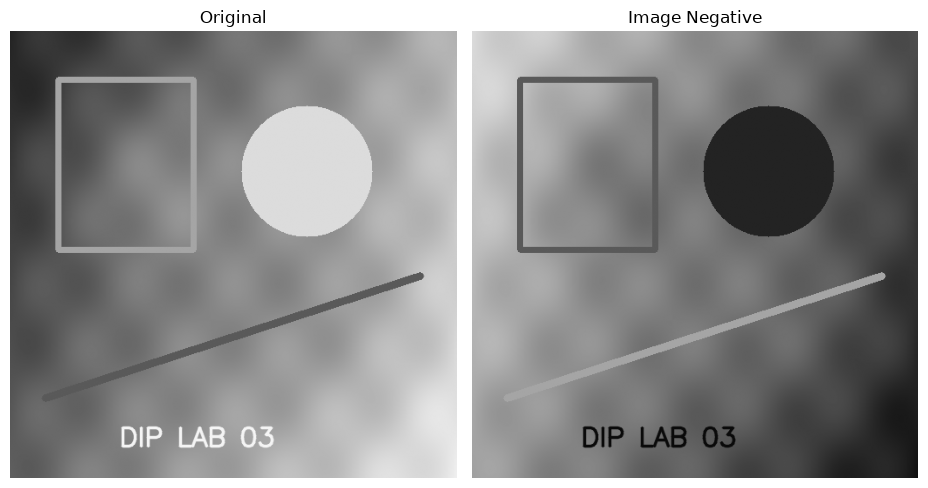

In [8]:
sample = np.array([30, 80, 128, 180, 240], dtype=np.uint8)
negative_sample = 255 - sample
double_negative = 255 - negative_sample
print("Negative:", negative_sample.tolist())
print("Negative applied again:", double_negative.tolist())
print("Restores original:", np.array_equal(sample, double_negative))

negative = 255 - original
show_images([original, negative], ["Original", "Image Negative"])

# Practical 5 – Gamma correction

Formula: `s = 255(r/255)^γ`. First normalize r to 0–1, raise it to γ, then scale back to 0–255. With this convention, γ < 1 brightens darker/mid-tone pixels, while γ > 1 darkens them. Both endpoints remain fixed: 0 maps to 0 and 255 maps to 255.

### Dry run

Input: `[0, 64, 128, 192, 255]`. Keep full precision until the final step, then truncate:

- γ = 0.5: scaled values approximately `[0, 127.7498, 180.6654, 221.2691, 255]`; final `[0, 127, 180, 221, 255]`.
- γ = 2.0: scaled values approximately `[0, 16.0627, 64.2510, 144.5647, 255]`; final `[0, 16, 64, 144, 255]`.

A slide example that rounds rather than truncates can differ by one intensity level (for example, 127.7498 rounds to 128 but truncates to 127).

gamma=0.5
 normalized: [0.0, 0.25098039215686274, 0.5019607843137255, 0.7529411764705882, 1.0]
 power: [0.0, 0.5009794328681196, 0.7084919084320762, 0.8677218312746247, 1.0]
 scaled: [0.0, 127.7497553813705, 180.66543665017943, 221.2690669750293, 255.0]
 final (truncate): [0, 127, 180, 221, 255]
gamma=2.0
 normalized: [0.0, 0.25098039215686274, 0.5019607843137255, 0.7529411764705882, 1.0]
 power: [0.0, 0.0629911572472126, 0.2519646289888504, 0.5669204152249134, 1.0]
 scaled: [0.0, 16.062745098039215, 64.25098039215686, 144.56470588235294, 255.0]
 final (truncate): [0, 16, 64, 144, 255]
Gamma 0.5 endpoints: [[0, 255]]
Gamma 2.0 endpoints: [[0, 255]]


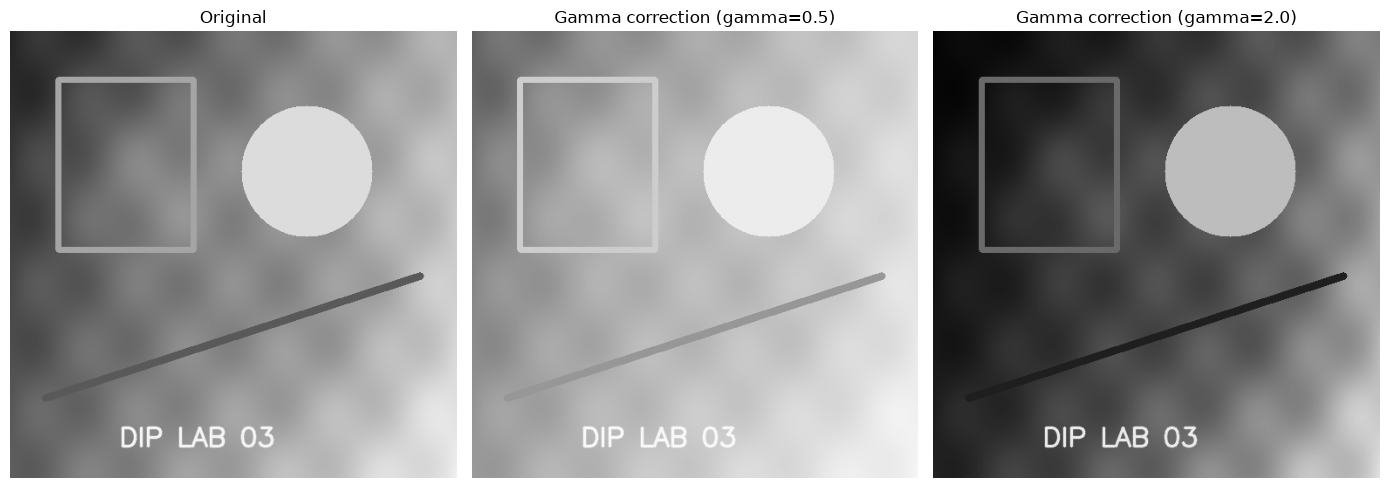

In [9]:
sample = np.array([0, 64, 128, 192, 255], dtype=np.float64)
for gamma in (0.5, 2.0):
    normalized = sample / 255.0
    powered = normalized ** gamma
    scaled = 255.0 * powered
    final = np.trunc(scaled).astype(np.uint8)
    print(f"gamma={gamma}")
    print(" normalized:", normalized.tolist())
    print(" power:", powered.tolist())
    print(" scaled:", scaled.tolist())
    print(" final (truncate):", final.tolist())

def gamma_transform(image, gamma):
    normalized = image.astype(np.float32) / 255.0
    return np.trunc(255.0 * (normalized ** gamma)).clip(0,255).astype(np.uint8)

gamma_05 = gamma_transform(original, 0.5)
gamma_20 = gamma_transform(original, 2.0)
print("Gamma 0.5 endpoints:", gamma_transform(np.array([[0,255]],dtype=np.uint8),0.5).tolist())
print("Gamma 2.0 endpoints:", gamma_transform(np.array([[0,255]],dtype=np.uint8),2.0).tolist())
show_images([original, gamma_05, gamma_20],
            ["Original", "Gamma correction (gamma=0.5)", "Gamma correction (gamma=2.0)"])

# Practical 6 – Grayscale histogram

A grayscale histogram counts how many pixels have each intensity from 0 through 255. It describes the frequency of intensity values, but it does not show where those pixels are located.

### Dry run

`A = [[0, 50, 50, 100], [100, 150, 200, 255]]`, so the total pixel count is 8.

| Intensity | Frequency | Probability |
|---:|---:|---:|
| 0 | 1 | 1/8 = 0.125 |
| 50 | 2 | 2/8 = 0.250 |
| 100 | 2 | 2/8 = 0.250 |
| 150 | 1 | 1/8 = 0.125 |
| 200 | 1 | 1/8 = 0.125 |
| 255 | 1 | 1/8 = 0.125 |

The frequencies sum to 8 and probabilities sum to 1.

Total pixels: 8
Intensity 0: frequency=1, probability=0.125
Intensity 50: frequency=2, probability=0.250
Intensity 100: frequency=2, probability=0.250
Intensity 150: frequency=1, probability=0.125
Intensity 200: frequency=1, probability=0.125
Intensity 255: frequency=1, probability=0.125
Frequency total: 8 Probability total: 1.0


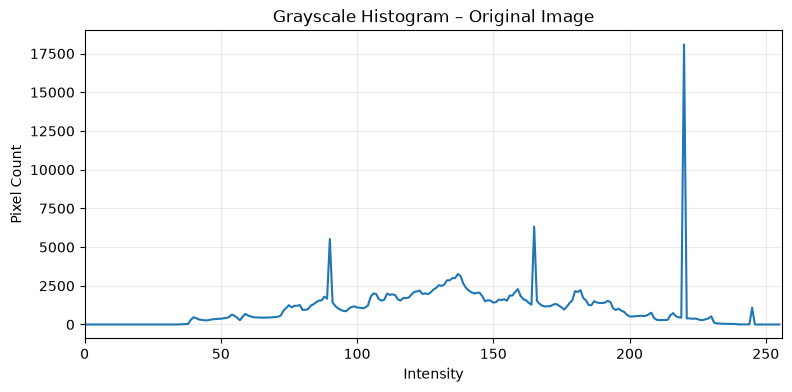

In [10]:
A = np.array([[0, 50, 50, 100], [100, 150, 200, 255]], dtype=np.uint8)
values, frequencies = np.unique(A, return_counts=True)
probabilities = frequencies / A.size
print("Total pixels:", A.size)
for value, frequency, probability in zip(values, frequencies, probabilities):
    print(f"Intensity {int(value)}: frequency={int(frequency)}, probability={probability:.3f}")
print("Frequency total:", int(frequencies.sum()), "Probability total:", float(probabilities.sum()))

hist = cv2.calcHist([original], [0], None, [256], [0, 256]).ravel()
plt.figure(figsize=(9,4))
plt.plot(np.arange(256), hist)
plt.xlim(0,256)
plt.title("Grayscale Histogram – Original Image")
plt.xlabel("Intensity")
plt.ylabel("Pixel Count")
plt.grid(alpha=0.25)
plt.show()

# Practical 7 – Global histogram equalization

`cv2.equalizeHist` spreads intensity levels using the cumulative distribution function (CDF). It can improve global contrast when the original intensities occupy a narrow range, but it can also make noise more visible.

### Dry run

Input `[50, 50, 100, 150]`; frequencies are 50:2, 100:1, 150:1. Cumulative counts are `[2, 3, 4]`, and CDF values are `[0.50, 0.75, 1.00]`. Thus CDFmin = 0.50.

- Mapping `255 × CDF`, rounded half upward: `[128, 191, 255]` for levels `[50, 100, 150]`; output list `[128, 128, 191, 255]`.
- Mapping `255 × (CDF − CDFmin)/(1 − CDFmin)`: `[0, 128, 255]`; output list `[0, 0, 128, 255]`.

The second mapping matches the standard OpenCV equalization mapping for this example.

Levels: [50, 100, 150]
Frequencies: [2, 1, 1]
Cumulative counts: [2, 3, 4]
CDF: [0.5, 0.75, 1.0] CDFmin: 0.5
255 x CDF mapping: [128, 191, 255] output: [128, 128, 191, 255]
Normalized mapping: [0, 128, 255] output: [0, 0, 128, 255]
OpenCV equalizeHist: [0, 0, 128, 255]


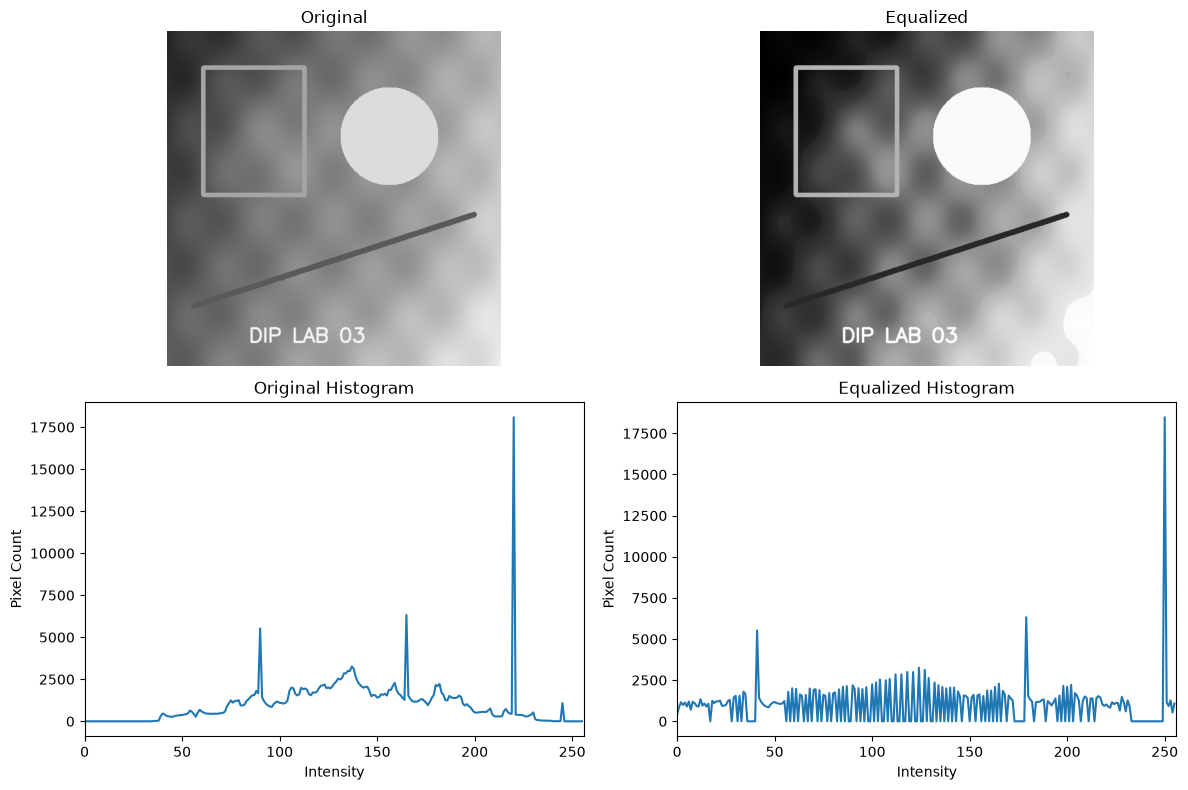

In [11]:
sample = np.array([50, 50, 100, 150], dtype=np.uint8)
levels, counts = np.unique(sample, return_counts=True)
cumulative_counts = np.cumsum(counts)
cdf = cumulative_counts / sample.size
cdf_min = cdf[np.flatnonzero(counts)[0]]

# Explicit half-up rounding for non-negative values.
map_cdf = np.floor(255 * cdf + 0.5).astype(np.uint8)
map_normalized = np.floor(255 * (cdf - cdf_min) / (1 - cdf_min) + 0.5).astype(np.uint8)
lookup_cdf = dict(zip(levels.tolist(), map_cdf.tolist()))
lookup_norm = dict(zip(levels.tolist(), map_normalized.tolist()))
out_cdf = [lookup_cdf[int(v)] for v in sample]
out_norm = [lookup_norm[int(v)] for v in sample]
print("Levels:", levels.tolist())
print("Frequencies:", counts.tolist())
print("Cumulative counts:", cumulative_counts.tolist())
print("CDF:", cdf.tolist(), "CDFmin:", float(cdf_min))
print("255 x CDF mapping:", map_cdf.tolist(), "output:", out_cdf)
print("Normalized mapping:", map_normalized.tolist(), "output:", out_norm)
print("OpenCV equalizeHist:", cv2.equalizeHist(sample.reshape(1,-1)).ravel().tolist())

equalized = cv2.equalizeHist(original)
original_hist = cv2.calcHist([original], [0], None, [256], [0,256]).ravel()
equalized_hist = cv2.calcHist([equalized], [0], None, [256], [0,256]).ravel()
fig, axes = plt.subplots(2,2,figsize=(12,8))
axes[0,0].imshow(original,cmap="gray",vmin=0,vmax=255); axes[0,0].set_title("Original")
axes[0,1].imshow(equalized,cmap="gray",vmin=0,vmax=255); axes[0,1].set_title("Equalized")
axes[1,0].plot(original_hist); axes[1,0].set_title("Original Histogram"); axes[1,0].set_xlim(0,256)
axes[1,1].plot(equalized_hist); axes[1,1].set_title("Equalized Histogram"); axes[1,1].set_xlim(0,256)
for ax in axes.flat: 
    if ax in axes[0]: ax.axis("off")
    else: ax.set_xlabel("Intensity"); ax.set_ylabel("Pixel Count")
plt.tight_layout(); plt.show()

# Practical 8 – CLAHE

CLAHE means Contrast Limited Adaptive Histogram Equalization. It equalizes small image regions (tiles) instead of using one mapping for the whole image. It is useful when lighting varies across the image. The `tileGridSize=(8, 8)` setting means 8 tiles across and 8 tiles down—not 8 × 8 pixels per tile. The clip limit restricts local histogram amplification, helping control noise.

### Simplified dry run

Histogram `[6, 2, 0, 0]`, absolute cap = 4:

- Clip counts: `[4, 2, 0, 0]`.
- Excess = 2. Redistribute equally across four bins: add 0.5 to each.
- New histogram: `[4.5, 2.5, 0.5, 0.5]`.
- Total = 8; CDF = `[0.5625, 0.875, 0.9375, 1.0]`.

Neighboring tile mappings are interpolated to avoid visible block boundaries. This simplified fractional redistribution is not OpenCV's exact integer redistribution, and the absolute cap of 4 is not the same as OpenCV's `clipLimit=2.0`.

Clipped histogram: [4.0, 2.0, 0.0, 0.0]
Excess: 2.0
Redistributed histogram: [4.5, 2.5, 0.5, 0.5]
New CDF: [0.5625, 0.875, 0.9375, 1.0]


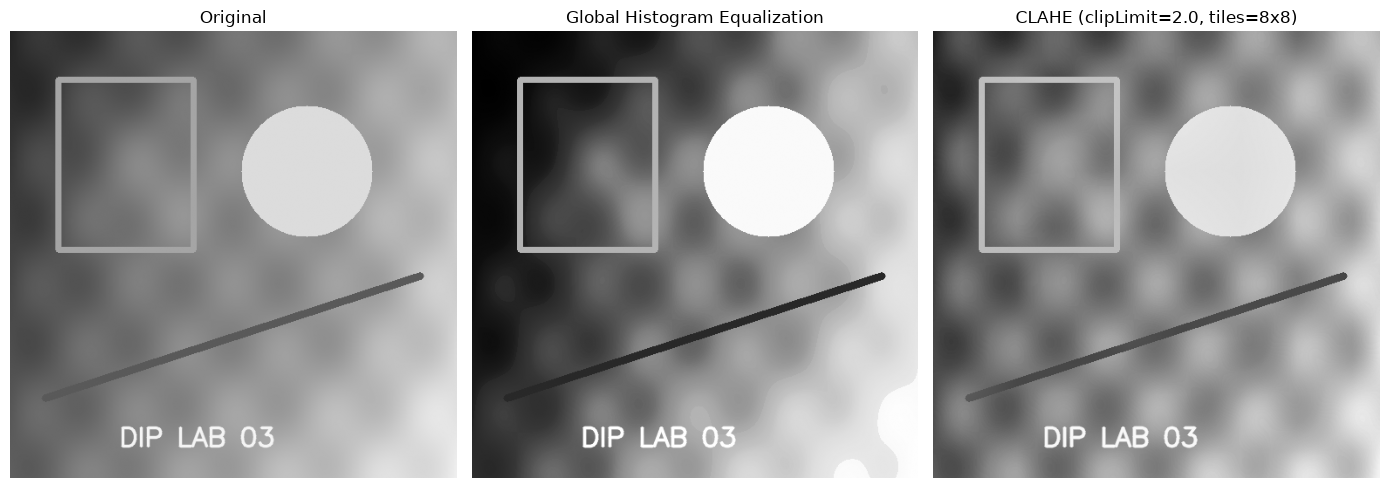

In [12]:
histogram = np.array([6,2,0,0], dtype=np.float64)
cap = 4
clipped = np.minimum(histogram, cap)
excess = float(np.sum(histogram - clipped))
redistributed = clipped + excess / len(histogram)
cdf = np.cumsum(redistributed) / np.sum(redistributed)
print("Clipped histogram:", clipped.tolist())
print("Excess:", excess)
print("Redistributed histogram:", redistributed.tolist())
print("New CDF:", cdf.tolist())

clahe_operator = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
clahe_image = clahe_operator.apply(original)
show_images([original, equalized, clahe_image],
            ["Original", "Global Histogram Equalization", "CLAHE (clipLimit=2.0, tiles=8x8)"])

# Practical 9 – Fixed binary thresholding

With `r > T`, a pixel becomes 255 (white) if it is strictly greater than T; otherwise it becomes 0 (black).

### Dry run

Input `[0, 80, 127, 128, 180, 255]`:

- T = 127 → `[0, 0, 0, 255, 255, 255]`; white-pixel count = 3.
- T = 180 → `[0, 0, 0, 0, 0, 255]`; white-pixel count = 1.

A pixel equal to the threshold is black because the rule is strictly greater than T.

T=127: [0, 0, 0, 255, 255, 255], white pixels=3
T=180: [0, 0, 0, 0, 0, 255], white pixels=1
Unique output values: [0, 255]


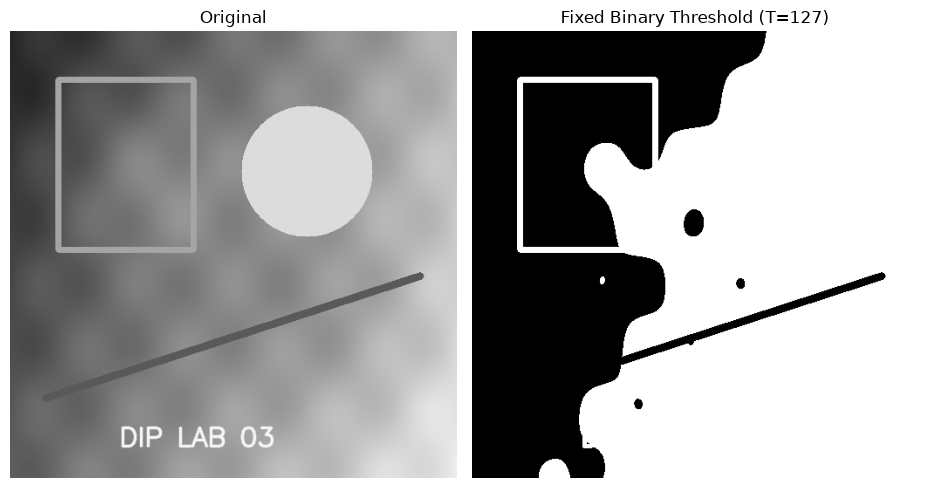

In [13]:
sample = np.array([0,80,127,128,180,255], dtype=np.uint8)
for threshold in (127,180):
    result = np.where(sample > threshold,255,0).astype(np.uint8)
    print(f"T={threshold}: {result.tolist()}, white pixels={int(np.count_nonzero(result==255))}")

_, fixed_threshold = cv2.threshold(original, 127, 255, cv2.THRESH_BINARY)
print("Unique output values:", np.unique(fixed_threshold).tolist())
show_images([original, fixed_threshold], ["Original", "Fixed Binary Threshold (T=127)"])

# Practical 10 – Otsu thresholding

Otsu's method automatically chooses a global threshold by maximizing between-class variance. For each candidate T, pixels are divided into class 0 (`r ≤ T`) and class 1 (`r > T`).

### Dry run

Input `[0, 1, 4, 5]`. Candidate scores `w0 w1 (μ0 − μ1)²`:

| T | w0 | w1 | μ0 | μ1 | Score |
|---:|---:|---:|---:|---:|---:|
| 0 | 0.25 | 0.75 | 0 | 3.3333 | 2.0833 |
| 1 | 0.50 | 0.50 | 0.5 | 4.5 | 4.0000 |
| 2 | 0.50 | 0.50 | 0.5 | 4.5 | 4.0000 |
| 3 | 0.50 | 0.50 | 0.5 | 4.5 | 4.0000 |
| 4 | 0.75 | 0.25 | 1.6667 | 5 | 2.0833 |

The maximum is tied at T = 1, 2, and 3. The required smallest tied threshold is T = 1. Predicted mask: `[0, 0, 255, 255]`.

T=0: w0=0.25, w1=0.75, mu0=0.0000, mu1=3.3333, score=2.0833
T=1: w0=0.50, w1=0.50, mu0=0.5000, mu1=4.5000, score=4.0000
T=2: w0=0.50, w1=0.50, mu0=0.5000, mu1=4.5000, score=4.0000
T=3: w0=0.50, w1=0.50, mu0=0.5000, mu1=4.5000, score=4.0000
T=4: w0=0.75, w1=0.25, mu0=1.6667, mu1=5.0000, score=2.0833
Smallest maximizing T: 1
Predicted mask: [0, 0, 255, 255]
OpenCV returned Otsu threshold: 147.0
Fixed threshold unique values: [0, 255]
Otsu threshold unique values: [0, 255]


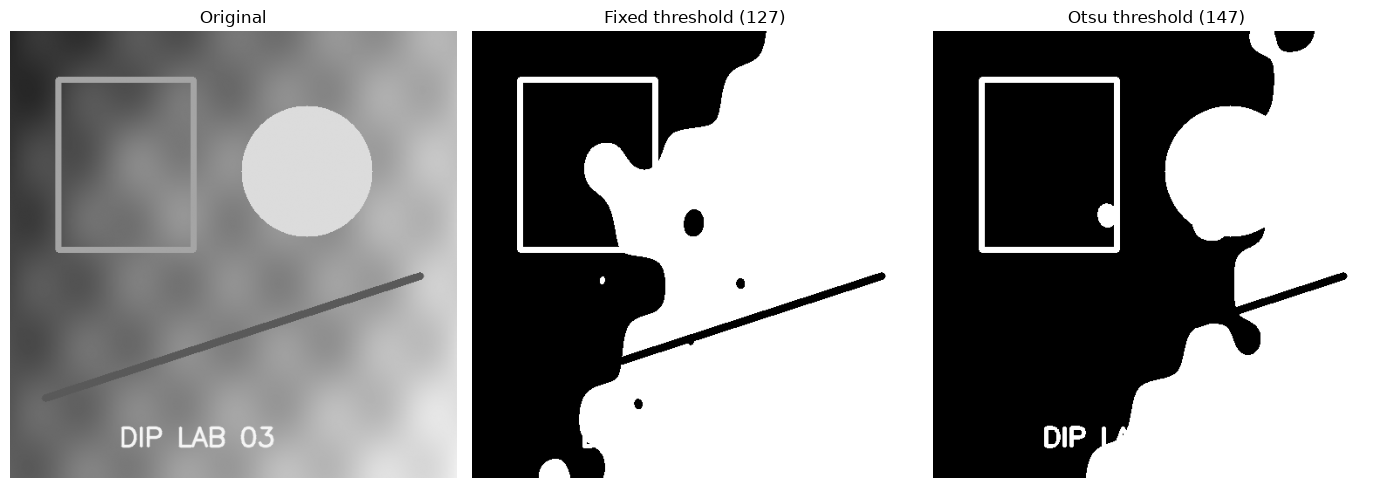

In [14]:
sample = np.array([0,1,4,5], dtype=np.uint8)
scores = []
for T in range(5):
    c0 = sample[sample <= T]
    c1 = sample[sample > T]
    if len(c0)==0 or len(c1)==0:
        score = float("-inf")
        w0, w1 = len(c0)/len(sample), len(c1)/len(sample)
        mu0 = float(np.mean(c0)) if len(c0) else float("nan")
        mu1 = float(np.mean(c1)) if len(c1) else float("nan")
    else:
        w0, w1 = len(c0)/len(sample), len(c1)/len(sample)
        mu0, mu1 = float(np.mean(c0)), float(np.mean(c1))
        score = w0*w1*(mu0-mu1)**2
    scores.append(score)
    print(f"T={T}: w0={w0:.2f}, w1={w1:.2f}, mu0={mu0:.4f}, mu1={mu1:.4f}, score={score:.4f}")
best_T = int(np.flatnonzero(np.array(scores)==np.max(scores))[0])
print("Smallest maximizing T:", best_T)
print("Predicted mask:", np.where(sample > best_T,255,0).astype(np.uint8).tolist())

otsu_T, otsu_mask = cv2.threshold(original, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
_, fixed_mask = cv2.threshold(original, 127, 255, cv2.THRESH_BINARY)
print("OpenCV returned Otsu threshold:", otsu_T)
print("Fixed threshold unique values:", np.unique(fixed_mask).tolist())
print("Otsu threshold unique values:", np.unique(otsu_mask).tolist())
show_images([original, fixed_mask, otsu_mask],
            ["Original", "Fixed threshold (127)", f"Otsu threshold ({otsu_T:.0f})"])

# Practical 11 – Adaptive Gaussian thresholding

Adaptive thresholding calculates a local threshold for each pixel from a neighborhood. With Gaussian weighting, nearby pixels contribute more strongly. The required image operation uses `blockSize=11` and `C=2`. Local thresholds can work better than one global threshold when illumination is uneven.

### Dry run

Neighborhood:
`[[100,100,100],[100,120,140],[140,140,140]]`

Gaussian weights:
`[[1,2,1],[2,4,2],[1,2,1]] / 16`

Weighted sum = `(100×1 + 100×2 + 100×1 + 100×2 + 120×4 + 140×2 + 140×1 + 140×2 + 140×1)/16 = 120`.

Threshold `T = mean − 2 = 118`. The center pixel 120 is white because 120 > 118. A pixel equal to 118 is black because the comparison is strictly greater than the threshold.

Weighted mean: 120.0
Local threshold: 118.0
Center pixel 120 classification: 255
Pixel equal to threshold classification: 0


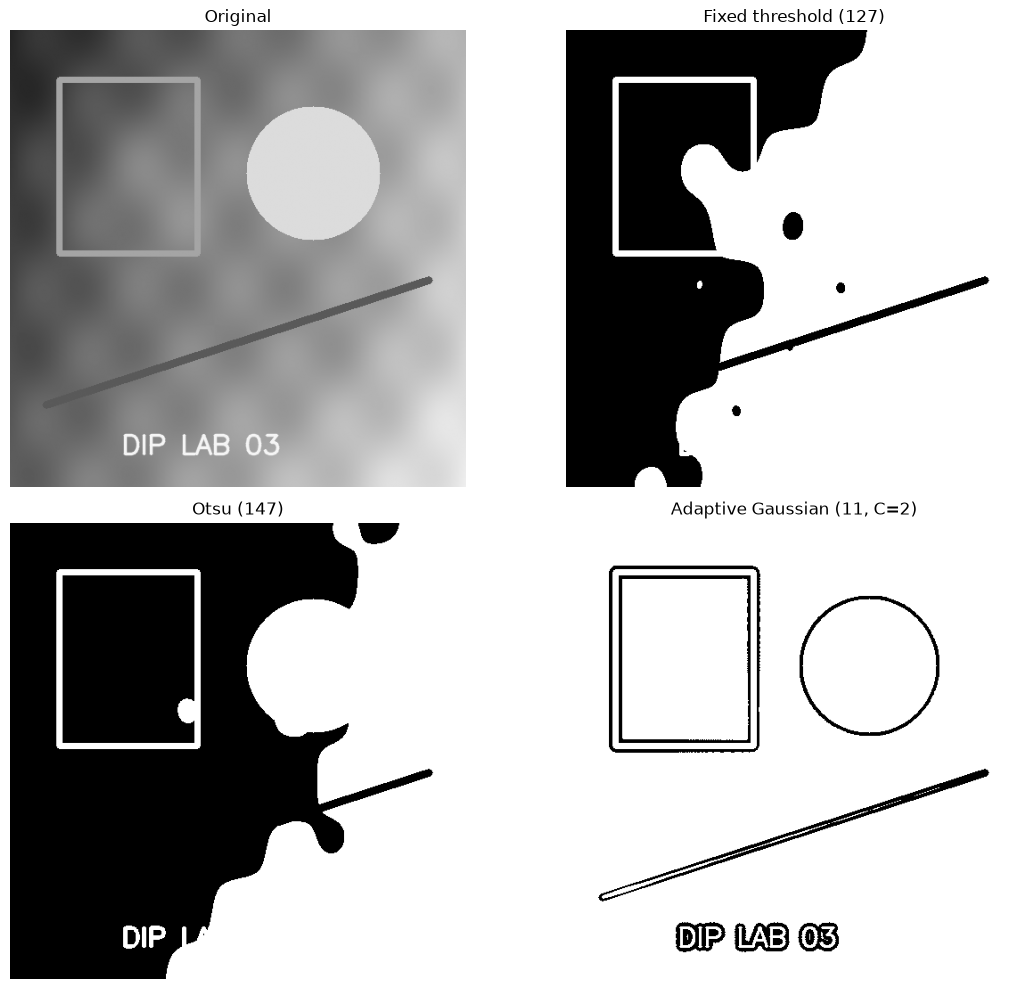

In [15]:
neighborhood = np.array([[100,100,100],[100,120,140],[140,140,140]], dtype=np.float64)
weights = np.array([[1,2,1],[2,4,2],[1,2,1]], dtype=np.float64) / 16
weighted_mean = float(np.sum(neighborhood * weights))
local_T = weighted_mean - 2
center_pixel = int(neighborhood[1,1])
print("Weighted mean:", weighted_mean)
print("Local threshold:", local_T)
print("Center pixel 120 classification:", 255 if center_pixel > local_T else 0)
print("Pixel equal to threshold classification:", 255 if local_T > local_T else 0)

adaptive = cv2.adaptiveThreshold(
    original, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    11, 2
)
show_images([original, fixed_mask, otsu_mask, adaptive],
            ["Original", "Fixed threshold (127)", f"Otsu ({otsu_T:.0f})", "Adaptive Gaussian (11, C=2)"],
            cols=2, figsize=(12,10))